In [1]:
#import necessary Libraries
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.metrics import r2_score,mean_absolute_error

In [2]:
#Load the Data
df = pd.read_csv('Bengaluru_House_Data.csv')
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


--------------Exploratory Data Analysis---------

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [4]:
df.isnull().sum()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

Society and balcony are having more Nan values
and area_type, availability, Society and balcony are the unwanted columns for the model 

In [5]:
#Drop unwanted columns
df = df.drop(["area_type","availability","society",'balcony'],axis=1)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   location    13319 non-null  object 
 1   size        13304 non-null  object 
 2   total_sqft  13320 non-null  object 
 3   bath        13247 non-null  float64
 4   price       13320 non-null  float64
dtypes: float64(2), object(3)
memory usage: 520.4+ KB


In [6]:
#Handling Missing values in Location
df['location'].value_counts()   #white field and sarjapur are having highest values we can replace with any one value
df['location'] = df['location'].fillna('Sarjapur  Road')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   location    13320 non-null  object 
 1   size        13304 non-null  object 
 2   total_sqft  13320 non-null  object 
 3   bath        13247 non-null  float64
 4   price       13320 non-null  float64
dtypes: float64(2), object(3)
memory usage: 520.4+ KB


In [7]:
#Handling Missing values in Size
df['size'].value_counts()  #2 BHK count is more
df['size']=df['size'].fillna('2 BHK')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   location    13320 non-null  object 
 1   size        13320 non-null  object 
 2   total_sqft  13320 non-null  object 
 3   bath        13247 non-null  float64
 4   price       13320 non-null  float64
dtypes: float64(2), object(3)
memory usage: 520.4+ KB


In [8]:
#Handling Missing values in bath
df['bath']=df['bath'].fillna(df['bath'].median())
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   location    13320 non-null  object 
 1   size        13320 non-null  object 
 2   total_sqft  13320 non-null  object 
 3   bath        13320 non-null  float64
 4   price       13320 non-null  float64
dtypes: float64(2), object(3)
memory usage: 520.4+ KB


In [9]:
#clean size column and convert into integer
df['size'].unique()
out = [int(i.split()[0]) for i in df['size']]
df['bhk'] = out
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   location    13320 non-null  object 
 1   size        13320 non-null  object 
 2   total_sqft  13320 non-null  object 
 3   bath        13320 non-null  float64
 4   price       13320 non-null  float64
 5   bhk         13320 non-null  int64  
dtypes: float64(2), int64(1), object(3)
memory usage: 624.5+ KB


In [10]:
#outliers
df[df['bhk']>20]

,location,size,total_sqft,bath,price,bhk
1718,2Electronic City Phase II,27 BHK,8000,27.0,230.0,27
4684,Munnekollal,43 Bedroom,2400,40.0,660.0,43


In [11]:
#clean total_sqft column
df['total_sqft'].unique()
def convert(a):
    l = a.split('-')
    if len(l)==2:
        return (float(l[0])+float(l[1]))/2
    try:
        return float(a)
    except:
        return None
df['total_sqft'] = df['total_sqft'].apply(convert)

In [12]:
df.head()

,location,size,total_sqft,bath,price,bhk
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,4
2,Uttarahalli,3 BHK,1440.0,2.0,62.00,3
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3
4,Kothanur,2 BHK,1200.0,2.0,51.00,2


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   location    13320 non-null  object 
 1   size        13320 non-null  object 
 2   total_sqft  13274 non-null  float64
 3   bath        13320 non-null  float64
 4   price       13320 non-null  float64
 5   bhk         13320 non-null  int64  
dtypes: float64(3), int64(1), object(2)
memory usage: 624.5+ KB


In [ ]:
#Price per sqr.ft
df['price_per_sqft'] = df['price']*100000/df['total_sqft']
df['price_per_sqft']

0         3699.810606
1         4615.384615
2         4305.555556
3         6245.890861
4         4250.000000
             ...     
13315     6689.834926
13316    11111.111111
13317     5258.545136
13318    10407.336319
13319     3090.909091
Name: price_per_sqft, Length: 13320, dtype: float64

In [15]:
df.describe()

,total_sqft,bath,price,bhk,price_per_sqft
count,13274.000000,13320.000000,13320.000000,13320.000000,1.327400e+04
mean,1559.626694,2.688814,112.565627,2.802778,7.907501e+03
std,1238.405258,1.338754,148.971674,1.294496,1.064296e+05
min,1.000000,1.000000,8.000000,1.000000,2.678298e+02
25%,1100.000000,2.000000,50.000000,2.000000,4.266865e+03
50%,1276.000000,2.000000,72.000000,3.000000,5.434306e+03
75%,1680.000000,3.000000,120.000000,3.000000,7.311746e+03
max,52272.000000,40.000000,3600.000000,43.000000,1.200000e+07


In [16]:
#cleaning location column
df['location'] = df['location'].apply(lambda x: x.strip())
df['location'].value_counts()

loc_lessthan_10 = df['location'].value_counts()
loc_lessthan_10 = loc_lessthan_10[loc_lessthan_10<=10]
loc_lessthan_10

location
Dodsworth Layout         10
Nagadevanahalli          10
Sadashiva Nagar          10
1st Block Koramangala    10
Gunjur Palya             10
                         ..
Hsr layout sector3        1
Thyagraj Nagar            1
Banagirinagar             1
Medaralli                 1
Chikkajala                1
Name: count, Length: 1053, dtype: int64

In [17]:
df['location'] = df['location'].apply(lambda x: 'other' if x in loc_lessthan_10 else x)

In [18]:
df['location'].value_counts()

location
other                        2885
Whitefield                    541
Sarjapur  Road                400
Electronic City               304
Kanakpura Road                273
                             ... 
Tindlu                         11
Marsur                         11
2nd Phase Judicial Layout      11
Thyagaraja Nagar               11
HAL 2nd Stage                  11
Name: count, Length: 242, dtype: int64

In [19]:
df.head()

,location,size,total_sqft,bath,price,bhk,price_per_sqft
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2,3699.810606
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,4,4615.384615
2,Uttarahalli,3 BHK,1440.0,2.0,62.00,3,4305.555556
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3,6245.890861
4,Kothanur,2 BHK,1200.0,2.0,51.00,2,4250.000000


Detecting and Handling Outliers

In [20]:
# Outliers in Total_sqft column
df.describe()

,total_sqft,bath,price,bhk,price_per_sqft
count,13274.000000,13320.000000,13320.000000,13320.000000,1.327400e+04
mean,1559.626694,2.688814,112.565627,2.802778,7.907501e+03
std,1238.405258,1.338754,148.971674,1.294496,1.064296e+05
min,1.000000,1.000000,8.000000,1.000000,2.678298e+02
25%,1100.000000,2.000000,50.000000,2.000000,4.266865e+03
50%,1276.000000,2.000000,72.000000,3.000000,5.434306e+03
75%,1680.000000,3.000000,120.000000,3.000000,7.311746e+03
max,52272.000000,40.000000,3600.000000,43.000000,1.200000e+07


Min value in total_sqr.ft is 1 we cant have a bhk room with 1 sqr ft. it is unrealistic data
so outliers are present in this column

In [21]:
#Total sqr.ft per bhk
(df['total_sqft']/df['bhk']).describe()

count    13274.000000
mean       575.074878
std        388.205175
min          0.250000
25%        473.333333
50%        552.500000
75%        625.000000
max      26136.000000
dtype: float64

In [22]:
#fetch the data where total sqr.ft per bhk is more than 300
df = df[(df['total_sqft']/df['bhk'])>=300]
df.describe()

,total_sqft,bath,price,bhk,price_per_sqft
count,12530.000000,12530.000000,12530.000000,12530.000000,12530.000000
mean,1594.564544,2.559537,111.382401,2.650838,6303.979357
std,1261.271296,1.077938,152.077329,0.976678,4162.237981
min,300.000000,1.000000,8.440000,1.000000,267.829813
25%,1116.000000,2.000000,49.000000,2.000000,4210.526316
50%,1300.000000,2.000000,70.000000,3.000000,5294.117647
75%,1700.000000,3.000000,115.000000,3.000000,6916.666667
max,52272.000000,16.000000,3600.000000,16.000000,176470.588235


Now we have min 300 which is proper

In [23]:
# to keep only realistic rows where the total square footage is at least 300 sq ft per BHK (bedroom).

df = df[df['total_sqft'] >= df['bhk'] * 300]
df.describe()

,total_sqft,bath,price,bhk,price_per_sqft
count,12530.000000,12530.000000,12530.000000,12530.000000,12530.000000
mean,1594.564544,2.559537,111.382401,2.650838,6303.979357
std,1261.271296,1.077938,152.077329,0.976678,4162.237981
min,300.000000,1.000000,8.440000,1.000000,267.829813
25%,1116.000000,2.000000,49.000000,2.000000,4210.526316
50%,1300.000000,2.000000,70.000000,3.000000,5294.117647
75%,1700.000000,3.000000,115.000000,3.000000,6916.666667
max,52272.000000,16.000000,3600.000000,16.000000,176470.588235


<Axes: xlabel='price_per_sqft'>

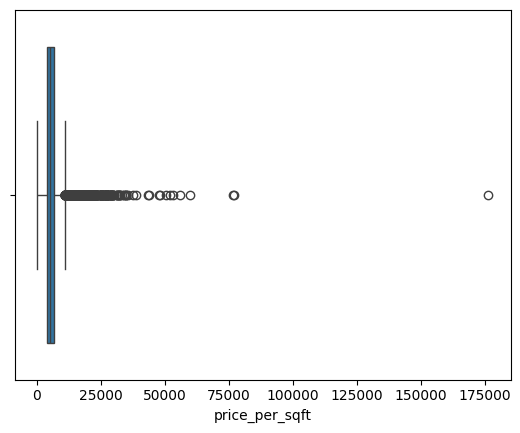

In [24]:
# sns.histplot(x='price_per_sqft',data=df)
sns.boxplot(x='price_per_sqft',data=df)

In [25]:
#Handling outliers in price_per_sqft
q1 = df['price_per_sqft'].quantile(0.25)
q3 = df['price_per_sqft'].quantile(0.75)

IQR = q3-q1

lower_bound = q1-0.5*IQR
upper_bound = q3+0.5*IQR

df = df[(df['price_per_sqft']>=lower_bound) & (df['price_per_sqft']<=upper_bound)]
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10350 entries, 0 to 13319
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   location        10350 non-null  object 
 1   size            10350 non-null  object 
 2   total_sqft      10350 non-null  float64
 3   bath            10350 non-null  float64
 4   price           10350 non-null  float64
 5   bhk             10350 non-null  int64  
 6   price_per_sqft  10350 non-null  float64
dtypes: float64(4), int64(1), object(2)
memory usage: 646.9+ KB


<Axes: xlabel='price_per_sqft'>

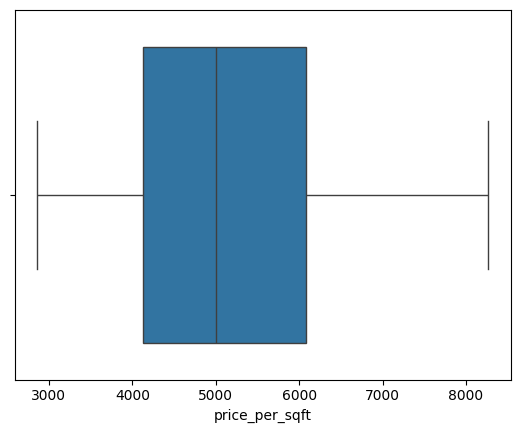

In [26]:
sns.boxplot(x='price_per_sqft',data=df)
# sns.histplot(x='price_per_sqft',data=df)

In [27]:
#Handling outliers in bhk

df = df[df['bhk']<=6]


In [28]:
#Handling outliers in bath column
# Keep rows where number of bathrooms is reasonable
df = df[df['bath'] < df['bhk'] + 2]

# It removes unrealistic rows where the number of bathrooms 
# (bath) is suspiciously high compared to the number of bedrooms (bhk).



In [29]:
df.head()

,location,size,total_sqft,bath,price,bhk,price_per_sqft
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2,3699.810606
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,4,4615.384615
2,Uttarahalli,3 BHK,1440.0,2.0,62.00,3,4305.555556
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3,6245.890861
4,Kothanur,2 BHK,1200.0,2.0,51.00,2,4250.000000


In [30]:
df = df.drop(['size','price_per_sqft'],axis=1)
df.head()

,location,total_sqft,bath,price,bhk
0,Electronic City Phase II,1056.0,2.0,39.07,2
1,Chikka Tirupathi,2600.0,5.0,120.00,4
2,Uttarahalli,1440.0,2.0,62.00,3
3,Lingadheeranahalli,1521.0,3.0,95.00,3
4,Kothanur,1200.0,2.0,51.00,2


In [31]:
df.reset_index(inplace=True)
df = df.drop('index',axis=1)

In [32]:
cleaned = df.copy()

In [33]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
df['location'] = encoder.fit_transform(df[['location']])

c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [34]:
X = df.drop('price',axis=1)
y = df['price']

In [35]:
Xtrain,Xtest,ytrain,ytest = train_test_split(X,y,test_size=0.3,random_state=42)

In [36]:
model = RandomForestRegressor(random_state=42)
params = {
    "n_estimators":[100,150,200,250,300],
    "max_depth":[3,4,5,6]
}

grid = GridSearchCV(estimator=model,param_grid=params,cv=5)
grid.fit(Xtrain,ytrain)

GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42),
             param_grid={'max_depth': [3, 4, 5, 6],
                         'n_estimators': [100, 150, 200, 250, 300]})

In [37]:
print("Best params: ",grid.best_params_)
print("Best score: ",grid.best_score_)

Best params:  {'max_depth': 6, 'n_estimators': 300}
Best score:  0.8395461926849966


In [38]:
print('Training Eff: ',grid.score(Xtrain,ytrain))
print('Testing Eff: ',grid.score(Xtest,ytest))

Training Eff:  0.8917382721428596
Testing Eff:  0.8362094809951321


In [39]:
ypred = grid.predict(Xtest)

In [40]:
print('R2: ',r2_score(ytest,ypred))
print('MAE: ',mean_absolute_error(ytest,ypred))

R2:  0.8362094809951321
MAE:  14.179109752705243


In [41]:
with open('RFmodel.pkl','wb') as file:
    pickle.dump(grid,file)

In [42]:
df.head()

,location,total_sqft,bath,price,bhk
0,78,1056.0,2.0,39.07,2
1,60,2600.0,5.0,120.00,4
2,225,1440.0,2.0,62.00,3
3,158,1521.0,3.0,95.00,3
4,150,1200.0,2.0,51.00,2


In [43]:
cleaned['encoded_loc'] = df['location']

In [44]:
df.describe()

,location,total_sqft,bath,price,bhk
count,10230.000000,10230.00000,10230.000000,10230.000000,10230.000000
mean,151.839101,1432.13379,2.367937,76.218467,2.495992
std,76.389312,773.66501,0.779985,54.319457,0.753740
min,0.000000,300.00000,1.000000,10.000000,1.000000
25%,92.000000,1100.00000,2.000000,47.000000,2.000000
50%,160.000000,1256.50000,2.000000,64.000000,2.000000
75%,234.000000,1577.00000,3.000000,89.112500,3.000000
max,240.000000,30400.00000,7.000000,2100.000000,6.000000


In [45]:
df.bath.unique()

array([2., 5., 3., 4., 1., 6., 7.])

In [46]:
df.shape

(10230, 5)

In [47]:
df.sample(5)

,location,total_sqft,bath,price,bhk
5874,226,1085.0,2.0,45.0,2
3791,28,1205.0,2.0,70.0,2
3462,240,1094.0,2.0,44.0,2
9884,82,1325.0,2.0,60.0,3
4822,171,1003.0,2.0,43.0,2


In [ ]:
# loc=
# sqft
# bhk
# bath
# grid.predict([[loc,sqft,bhk,bath]])